# 教科書の平均・共分散行列を使うポテンシャル関数法（双対パーセプトロン）

**教科書 p.27 式(2.8)〜(2.11)** の4つの正規分布をもとに、2クラスの人工データを作ります。クラス $\omega_1$ は $(\mu_{11},\Sigma_{11})$ と $(\mu_{21},\Sigma_{21})$ の混合、クラス $\omega_2$ は $(\mu_{12},\Sigma_{12})$ と $(\mu_{22},\Sigma_{22})$ の混合です。

- データ生成：各分布 $\mathcal N(\mu,\Sigma)$ から乱数生成（混合比は**各クラス内で 1:1 と仮定**）。元の図と完全一致する座標ではありません。
- カーネル：教科書 式(4.7) のガウス型ポテンシャル関数。標準設定 $\sigma=2.0$。
- 学習：式(4.9)〜(4.12) に従い、誤分類時に $\alpha_k\leftarrow\alpha_k+1$。
- 出力：生成点、等高線・決定境界、寄与ベクトル、更新履歴、$\sigma$ 比較。

**ポイント**：共分散行列は学習データを*生成する*ためのパラメータであり、双対パーセプトロンはそれらを直接最適化しません。学習されるのは $\alpha_k$ です。

学習の目的・実験結果・考察・実行方法は[テーマのREADME](../README.md)にまとめています。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['axes.grid'] = True
rng = np.random.default_rng(42)


## 1. 教科書の4つの正規分布からデータを生成

共分散行列の対角成分は分散、非対角成分は共分散です。$\omega_1$、$\omega_2$ はそれぞれ **2つの正規分布の混合**とします。`n_per_component` と `seed` を変えて実験できます。

X shape: (260, 2) class counts: (array([-1,  1]), array([130, 130]))
omega1-1: mean=[-2.   1.7], covariance=
[[0.659 0.453]
 [0.453 0.399]]

omega1-2: mean=[0.6 1.2], covariance=
[[ 0.197 -0.185]
 [-0.185  0.638]]

omega2-1: mean=[ 1.2 -2.2], covariance=
[[1.236 0.36 ]
 [0.36  0.168]]

omega2-2: mean=[-1.7 -1.6], covariance=
[[ 0.242 -0.045]
 [-0.045  0.398]]



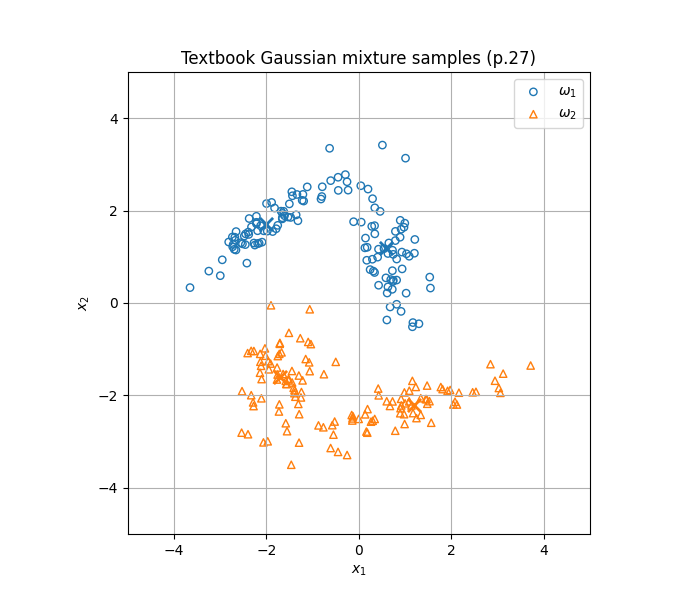

In [2]:
# 教科書 p.27 式(2.8)〜(2.11) の値をそのまま使用
mu11 = np.array([-2.0,  1.7])
Sigma11 = np.array([[0.659,  0.453],
                    [0.453,  0.399]])

mu21 = np.array([ 0.6,  1.2])
Sigma21 = np.array([[ 0.197, -0.185],
                    [-0.185,  0.638]])

mu12 = np.array([ 1.2, -2.2])
Sigma12 = np.array([[1.236, 0.360],
                    [0.360, 0.168]])

mu22 = np.array([-1.7, -1.6])
Sigma22 = np.array([[ 0.242, -0.045],
                    [-0.045,  0.398]])

components = [
    ('omega1-1', mu11, Sigma11, +1),
    ('omega1-2', mu21, Sigma21, +1),
    ('omega2-1', mu12, Sigma12, -1),
    ('omega2-2', mu22, Sigma22, -1),
]

n_per_component = 65  # 各成分の標本数。4成分で合計260点
seed = 42
rng = np.random.default_rng(seed)

parts, labels = [], []
for name, mu, cov, label in components:
    assert np.allclose(cov, cov.T), name + ': not symmetric'
    assert np.linalg.eigvalsh(cov).min() > 0, name + ': not positive definite'
    Xi = rng.multivariate_normal(mu, cov, size=n_per_component)
    parts.append(Xi)
    labels.append(np.full(n_per_component, label, dtype=int))

X = np.vstack(parts)
y = np.concatenate(labels)
X1, X2 = X[y == 1], X[y == -1]
print('X shape:', X.shape, 'class counts:', np.unique(y, return_counts=True))
for name, mu, cov, label in components:
    print(f'{name}: mean={mu}, covariance=\n{cov}\n')

# データ分布：元の教科書の例に近い曲線状の配置
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(X1[:, 0], X1[:, 1], s=28, facecolors='none', edgecolors='tab:blue', label=r'$\omega_1$')
ax.scatter(X2[:, 0], X2[:, 1], s=28, marker='^', facecolors='none', edgecolors='tab:orange', label=r'$\omega_2$')
for name, mu, cov, label in components:
    ax.scatter(*mu, marker='x', s=90, linewidths=2, color='tab:blue' if label == 1 else 'tab:orange')
ax.set(xlim=(-5, 5), ylim=(-5, 5), xlabel='$x_1$', ylabel='$x_2$',
       title='Textbook Gaussian mixture samples (p.27)')
ax.set_aspect('equal', adjustable='box')
ax.legend()
plt.show()

## 2. ポテンシャル関数 $K(x,z)$

$K(x,z)=\exp\!\left(-\frac{\|x-z\|^2}{2\sigma^2}\right)$

距離が小さいほど値は1に近く、距離が大きいほど0に近づきます。$\sigma$ は影響範囲です。


Gram matrix shape: (260, 260) ; diagonal: [1. 1. 1. 1.]


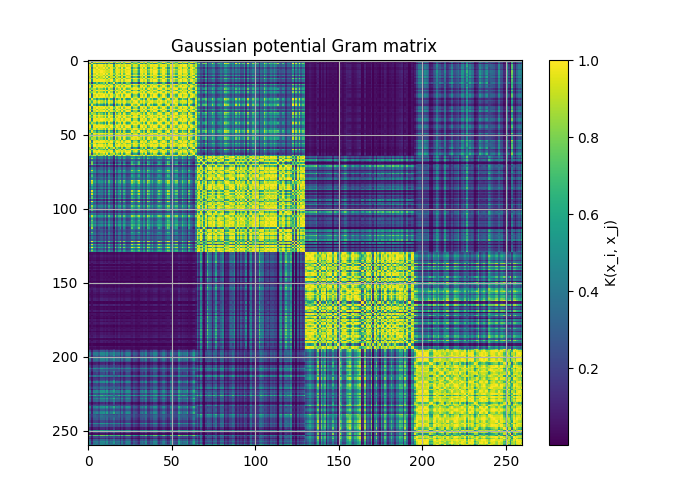

In [3]:
def gaussian_potential(A, B, sigma):
    """A:(m,d), B:(n,d) -> K:(m,n) with K_ij=exp(-||A_i-B_j||^2/(2*sigma^2))."""
    A = np.atleast_2d(np.asarray(A, dtype=float))
    B = np.atleast_2d(np.asarray(B, dtype=float))
    if sigma <= 0:
        raise ValueError('sigma must be positive')
    d2 = np.sum((A[:, None, :] - B[None, :, :])**2, axis=2)
    return np.exp(-d2 / (2 * sigma**2))

sigma = 2.0  # 教科書4.4節の設定
G = gaussian_potential(X, X, sigma)
print('Gram matrix shape:', G.shape, '; diagonal:', G.diagonal()[:4])
plt.imshow(G, interpolation='nearest', cmap='viridis', aspect='auto')
plt.colorbar(label='K(x_i, x_j)')
plt.title('Gaussian potential Gram matrix')
plt.show()

## 3. 双対パーセプトロンの学習

教科書の式(4.9)：

$$g(x)=\sum_{k=1}^n \alpha_k b_k K(x,x_k),\qquad b_k\in\{+1,-1\}.$$

初期値は $\alpha_k=0$、学習点 $x_k$ に対して **$b_k g(x_k)\le 0$** なら **$\alpha_k\leftarrow\alpha_k+1$** とします。

- 正しく識別できたら更新しません。
- 決定境界上（$g=0$）も更新対象です。
- ここでは見やすさのため、学習点を **毎エポック同じ順序** で走査します。全件正解なら停止します。
- データの重なりや丸め誤差により、指定回数内に完全収束しない場合もあります。

**学習率**は1、$\alpha$ の初期値は0です。分類が収束しないケースもあるため、最大エポック数を設けています。

In [4]:
class PotentialDualPerceptron:
    def __init__(self, sigma=1.2, max_epochs=600):
        self.sigma = sigma
        self.max_epochs = max_epochs

    def fit(self, X, y):
        self.X_train_ = np.asarray(X, dtype=float).copy()
        self.y_train_ = np.asarray(y, dtype=int).copy()
        if set(np.unique(self.y_train_)) - {-1, 1}:
            raise ValueError('labels must be -1 or +1')
        n = len(self.y_train_)
        self.alpha_ = np.zeros(n, dtype=int)
        gram = gaussian_potential(self.X_train_, self.X_train_, self.sigma)
        self.history_ = []
        self.snapshots_ = {0: self.alpha_.copy()}
        self.total_updates_ = 0
        self.converged_ = False

        for epoch in range(1, self.max_epochs + 1):
            updates = 0
            for k in range(n):
                # 現時点の学習済み係数で x_k を判定
                score = gram[k] @ (self.alpha_ * self.y_train_)
                if self.y_train_[k] * score <= 0:
                    self.alpha_[k] += 1  # 教科書式 (4.12)
                    updates += 1
            self.total_updates_ += updates
            scores = gram @ (self.alpha_ * self.y_train_)
            mistakes = int(np.count_nonzero(self.y_train_ * scores <= 0))
            self.history_.append((epoch, updates, mistakes, np.count_nonzero(self.alpha_)))
            if epoch in (1, 5, 20, 50, 100, self.max_epochs):
                self.snapshots_[epoch] = self.alpha_.copy()
            if mistakes == 0:
                self.converged_ = True
                self.snapshots_[epoch] = self.alpha_.copy()
                break
        self.n_epochs_ = epoch
        return self

    def decision_function(self, X_new, alpha=None):
        X_new = np.atleast_2d(np.asarray(X_new, dtype=float))
        if alpha is None:
            alpha = self.alpha_
        # 非ゼロ係数の点のみ計算する：寄与ベクトル
        active = np.flatnonzero(alpha)
        if active.size == 0:
            return np.zeros(len(X_new))
        K = gaussian_potential(X_new, self.X_train_[active], self.sigma)
        return K @ (alpha[active] * self.y_train_[active])

    def predict(self, X_new):
        return np.where(self.decision_function(X_new) >= 0, 1, -1)

model = PotentialDualPerceptron(sigma=sigma, max_epochs=600).fit(X, y)
print(f'epochs: {model.n_epochs_}; converged: {model.converged_}')
print(f'total updates: {model.total_updates_}')
print(f'nonzero alpha (contributors): {np.count_nonzero(model.alpha_)} / {len(model.alpha_)}')
print(f'training accuracy: {(model.predict(X) == y).mean():.3f}')
print('first 20 alpha:', model.alpha_[:20])

epochs: 4; converged: True
total updates: 12
nonzero alpha (contributors): 11 / 260
training accuracy: 1.000
first 20 alpha: [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]


## 4. 何を学習したか確認する

最終的に得られるのは $\alpha=(\alpha_1,\ldots,\alpha_n)$ です。$\alpha_k>0$ となった学習点だけが、予測時に識別関数に寄与します。

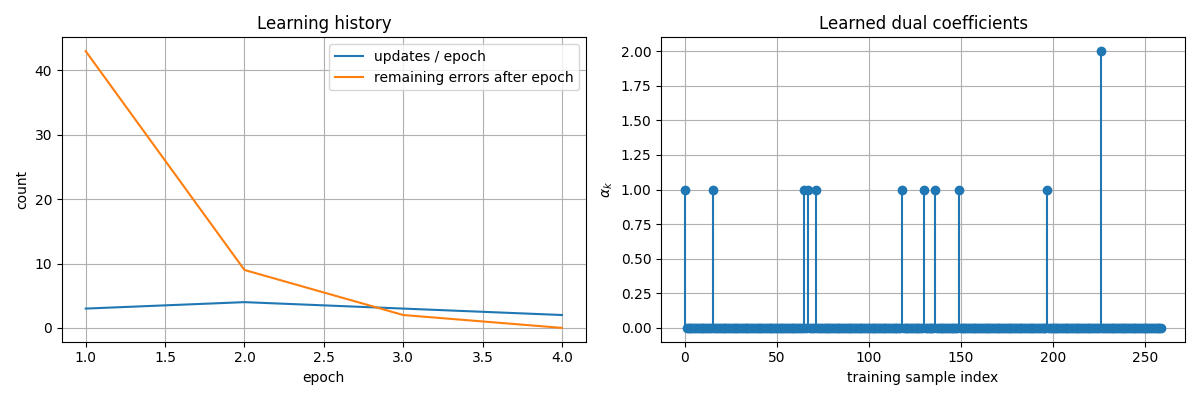

インデックス : αの値
0 : 1
15 : 1
65 : 1
67 : 1
71 : 1
118 : 1
130 : 1
136 : 1
149 : 1
197 : 1
226 : 2


In [5]:
hist = np.array(model.history_)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist[:, 0], hist[:, 1], label='updates / epoch')
axes[0].plot(hist[:, 0], hist[:, 2], label='remaining errors after epoch')
axes[0].set(xlabel='epoch', ylabel='count', title='Learning history')
axes[0].legend()
axes[1].stem(np.arange(len(X)), model.alpha_, basefmt=' ')
axes[1].set(xlabel='training sample index', ylabel=r'$\alpha_k$', title='Learned dual coefficients')
plt.tight_layout()
plt.show()

# αが0より大きい（更新された）要素のインデックスを取得
active_indices = np.flatnonzero(model.alpha_)

print("インデックス : αの値")
for idx in active_indices:
    print(f"{idx} : {model.alpha_[idx]}")

## 5. 決定境界と寄与ベクトル

識別関数 $g(x)=0$ が決定境界です。黒い大きな印は $\alpha_k>0$ の学習点です。

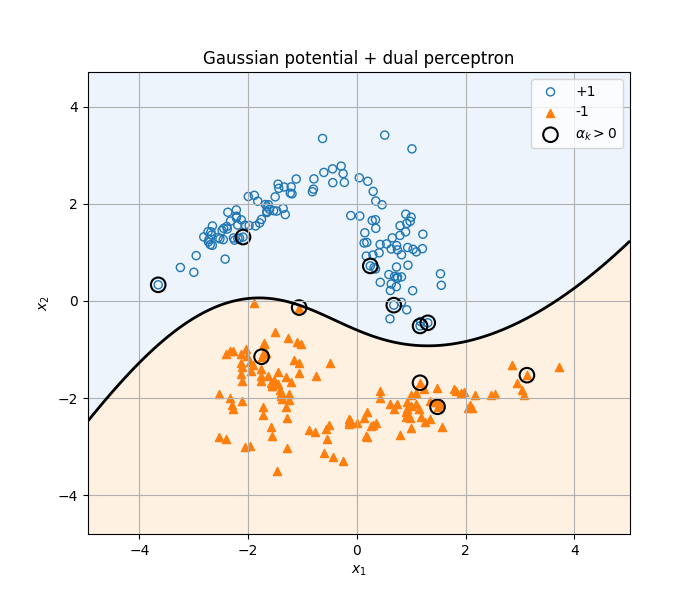

In [6]:
def plot_boundary(model, X, y, ax=None, alpha=None, title=''):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    if alpha is None:
        alpha = model.alpha_
    pad = 1.3
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-pad, X[:, 0].max()+pad, 180),
                         np.linspace(X[:, 1].min()-pad, X[:, 1].max()+pad, 180))
    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model.decision_function(grid, alpha=alpha).reshape(xx.shape)
    ax.contourf(xx, yy, scores, levels=[-1e10, 0, 1e10], colors=['#ffe4c7','#dceafa'], alpha=.5)
    if scores.min() < 0 < scores.max():
        ax.contour(xx, yy, scores, levels=[0], colors='black', linewidths=2)
    ax.scatter(X[y==1, 0], X[y==1, 1], facecolors='none', edgecolors='tab:blue', s=34, label='+1')
    ax.scatter(X[y==-1, 0], X[y==-1, 1], marker='^', c='tab:orange', s=34, label='-1')
    active = alpha>0
    if np.any(active):
        ax.scatter(X[active, 0], X[active, 1], s=110, facecolors='none', edgecolors='black', linewidths=1.5, label=r'$\alpha_k>0$')
    ax.set(xlabel='$x_1$', ylabel='$x_2$', title=title)
    return ax

fig, ax = plt.subplots(figsize=(7, 6))
plot_boundary(model, X, y, ax, title='Gaussian potential + dual perceptron')
ax.legend(loc='best')
plt.show()

## 6. 学習途中の決定境界

更新回数が増えることで $g(x)$ の形が変化していきます。

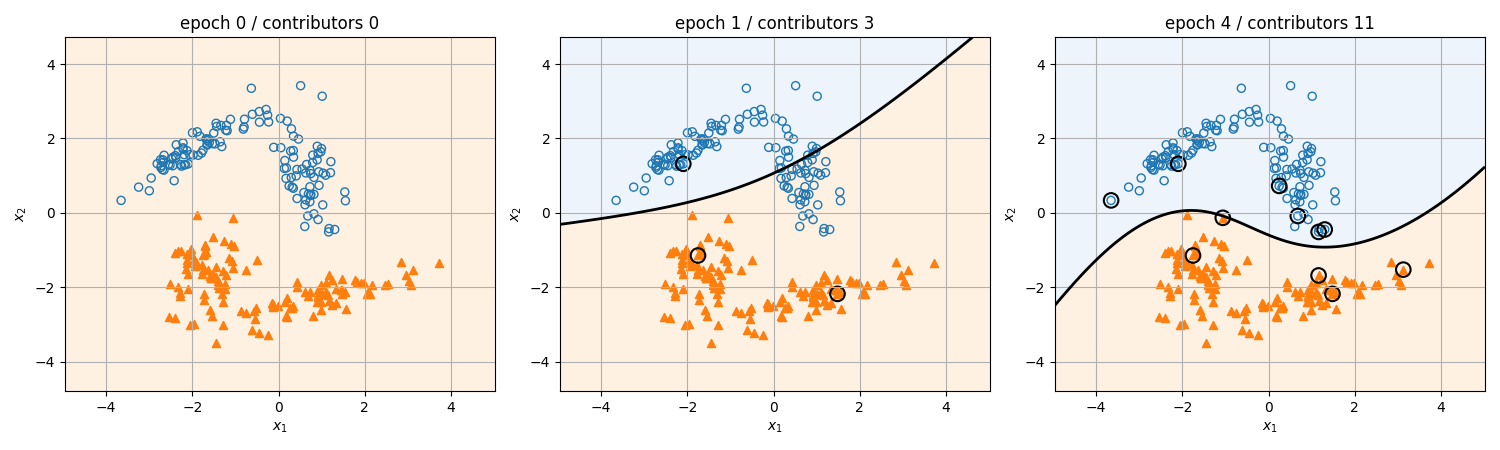

In [7]:
snap_items = list(model.snapshots_.items())
# 初期状態・途中・最終状態を選択
selected = [snap_items[0]]
if len(snap_items) > 2:
    selected += [snap_items[len(snap_items)//2]]
selected += [snap_items[-1]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (ep, alpha) in zip(axes, selected):
    plot_boundary(model, X, y, ax, alpha=alpha, title=f'epoch {ep} / contributors {(alpha>0).sum()}')
plt.tight_layout()
plt.show()

## 7. 未知データの予測を手計算に対応させる

$x$ に対し、各寄与ベクトルの寄与 $\alpha_k b_k K(x,x_k)$ を計算して合計します。

In [8]:
x_new = np.array([[0.0, 0.0], [1.5, -0.5], [-1.5, 0.6]])
active = np.flatnonzero(model.alpha_)
for x_new_i in x_new:
    Kvals = gaussian_potential(x_new_i[None, :], X[active], model.sigma)[0]
    contributions = model.alpha_[active] * y[active] * Kvals
    score = contributions.sum()
    print(f'x={x_new_i}, g(x)={score:+.4f}, predicted={1 if score>=0 else -1}, contributions={len(active)}')
    assert np.allclose(score, model.decision_function(x_new_i)[0])

x=[0. 0.], g(x)=+0.5874, predicted=1, contributions=11
x=[ 1.5 -0.5], g(x)=+0.4484, predicted=1, contributions=11
x=[-1.5  0.6], g(x)=+0.4544, predicted=1, contributions=11


## 8. $\sigma$ の比較（別々に学習する）

教科書の実験の中心は $\sigma=2.0$ です。幅を変えると更新回数、寄与ベクトル数、決定境界が変わります。

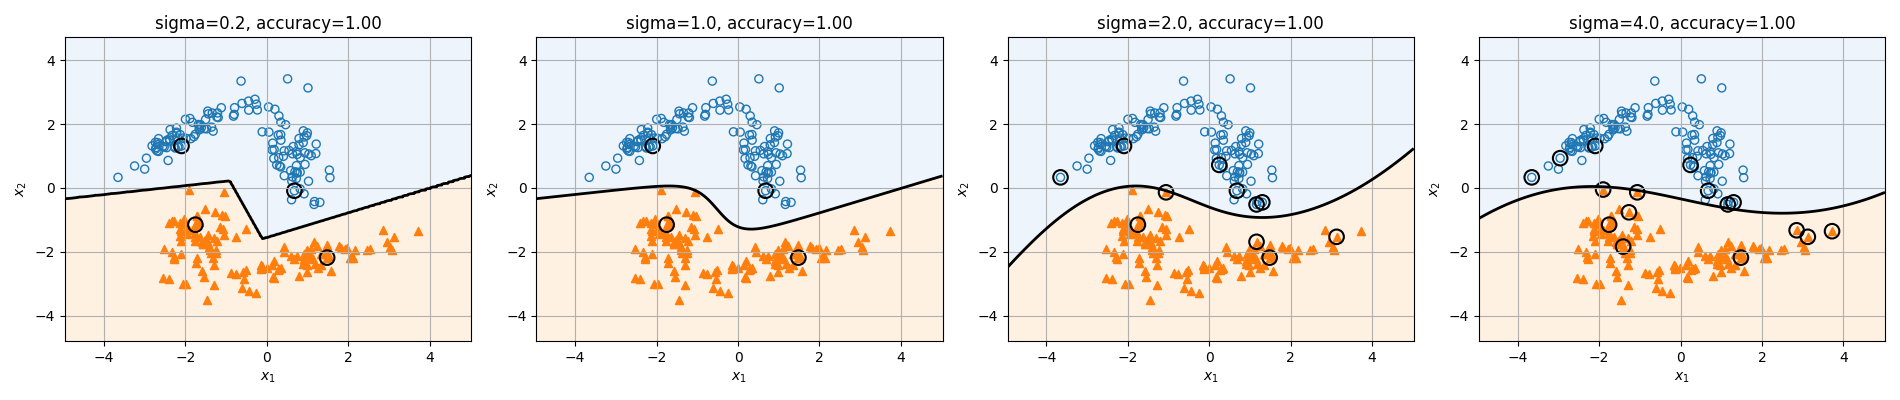

sigma | epochs | converged | contributors | train accuracy
0.2 | 2 | True | 4 | 1.0
1.0 | 2 | True | 4 | 1.0
2.0 | 4 | True | 11 | 1.0
4.0 | 28 | True | 16 | 1.0


In [9]:
sigmas = [0.2, 1.0, 2.0, 4.0]
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
summary = []
for ax, s in zip(axes, sigmas):
    m = PotentialDualPerceptron(sigma=s, max_epochs=250).fit(X, y)
    accuracy = (m.predict(X) == y).mean()
    summary.append((s, m.n_epochs_, m.converged_, np.count_nonzero(m.alpha_), round(float(accuracy),3)))
    plot_boundary(m, X, y, ax, title=f'sigma={s}, accuracy={accuracy:.2f}')
plt.tight_layout()
plt.show()
print('sigma | epochs | converged | contributors | train accuracy')
for row in summary: print(*row, sep=' | ')

## 9. この実験の読み方

- **データ生成**：教科書の4組の $\mu,\Sigma$ で2クラスの混合正規分布を作る（混合比1:1はこのNotebookの設定）。
- **ポテンシャル関数**：$K(x,x_k)=\exp(-\|x-x_k\|^2/(2\sigma^2))$。
- **学習**：誤分類（または境界上）なら $\alpha_k\leftarrow\alpha_k+1$。実際に学習するのは $\alpha$。
- **予測**：$g(x)=\sum_k\alpha_kb_kK(x,x_k)$ の符号で分類。$\alpha_k>0$ の点だけを使える。
- **注意**：サンプル乱数と個数が教科書の実験と同じとは限らないため、更新回数や寄与ベクトル数も完全一致する必要はありません。

## 参考資料と評価の範囲

石井健一郎・前田英作 著『続々・わかりやすいパターン認識 線形から非線形へ』オーム社、2022年。ISBN: 978-4-274-22947-3。
[出版社の書籍紹介](https://www.ohmsha.co.jp/book/9784274229473.html)

データ生成はp.27の式(2.8)〜(2.11)、ポテンシャル関数と学習則は第4章の式(4.7)、式(4.9)〜(4.12)を参照した学習記録です。
混合比・乱数・標本数はこのNotebookの設定であり、教科書の実験の完全再現ではありません。

正解率は学習データ上の値です。第7節の3点は予測スコアの計算確認用で、正解ラベルを用意したテスト評価ではありません。
今後は独立したテストデータ、別の乱数シード、学習順序の影響を検証します。

再実行の検証環境ではNumPyの行列積でRuntimeWarningが一部発生しました。別計算との照合結果と評価の範囲は[READMEの実行確認](../README.md#実行確認)を参照してください。
